# GAN Augmentation Phase 3: Decision-Level Optimization

This report evaluates the Weighted Ensemble (Original + Phase 2) and Per-Class Threshold Tuning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from xgboost import XGBClassifier
from ensemble import WeightedEnsemble
from threshold_tuning import ThresholdTuner

# 1. Load Data
real_df = pd.read_csv('../ml_training/dataset/unsw_nb_cleaned.csv')
features = ['proto', 'state', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'ct_srv_src', 'ct_dst_ltm']

# Recreate test set
X_real = real_df[features].copy()
y_real = real_df['attack_cat'].copy()
X_train, X_test, y_train, y_test = train_test_split(X_real, y_real, test_size=0.15, random_state=42, stratify=y_real)

# Preprocess
le_dict = {}
for c in ['proto', 'state']:
    le = LabelEncoder()
    le.fit(X_train[c].astype(str))
    X_test.loc[:, c] = X_test[c].map(lambda s: le.transform([s])[0] if s in le.classes_ else -1)

scaler = joblib.load('../ml_training/artifacts_improved/scaler.pkl')
label_encoder = joblib.load('../ml_training/artifacts_improved/label_encoder.pkl')
X_test_scaled = scaler.transform(X_test)
y_test_enc = label_encoder.transform(y_test)
classes = label_encoder.classes_

# 2. Load Models
xgb_orig = XGBClassifier()
xgb_orig.load_model('finetune/xgboost_original.json')

xgb_v2 = joblib.load('finetune_v2/xgboost_finetuned_v2.pkl')

# Initialize Ensemble
ensemble = WeightedEnsemble(xgb_orig, xgb_v2, weight_orig=0.6, weight_phase2=0.4)

# 3. Threshold Tuning (Using same logic as in run_phase_3)
target_classes = ['Analysis', 'Backdoor', 'Shellcode']
target_indices = [label_encoder.transform([c])[0] for c in target_classes]
tuner = ThresholdTuner(target_indices)

# We use the test set for the final report display
probs_ensemble = ensemble.predict_proba(X_test_scaled)

# Load tuned thresholds (assuming run_phase_3 saved them)
try:
    tuner.thresholds = joblib.load('finetune_v2/optimal_thresholds.pkl')
    print("Loaded optimal thresholds:", tuner.thresholds)
except:
    print("Optimal thresholds not found, using default 0.5")

# 4. Predict
y_pred_orig = xgb_orig.predict(X_test_scaled)
y_pred_v2 = xgb_v2.predict(X_test_scaled)
y_pred_ens = ensemble.predict(X_test_scaled)
y_pred_tuned = tuner.predict_with_thresholds(probs_ensemble)

# Summary
def get_metrics(y_true, y_pred, name):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro')
    }

results = [
    get_metrics(y_test_enc, y_pred_orig, "XGB Original"),
    get_metrics(y_test_enc, y_pred_v2, "XGB Phase 2"),
    get_metrics(y_test_enc, y_pred_ens, "Weighted Ensemble"),
    get_metrics(y_test_enc, y_pred_tuned, "Ensemble + Threshold Tuning")
]
summary_df = pd.DataFrame(results)
print("\nComparison Summary:")
print(summary_df)

print("\nPhase 3 Optimized Model Report:")
print(classification_report(y_test_enc, y_pred_tuned, target_names=classes))


Loaded optimal thresholds: {np.int64(0): np.float64(0.45000000000000007), np.int64(1): np.float64(0.40000000000000013), np.int64(8): np.float64(0.3500000000000001)}

Comparison Summary:
                         Model  Accuracy  Macro F1
0                 XGB Original  0.738841  0.525990
1                  XGB Phase 2  0.802677  0.599899
2            Weighted Ensemble  0.788951  0.588937
3  Ensemble + Threshold Tuning  0.787925  0.586926

Phase 3 Optimized Model Report:
                precision    recall  f1-score   support

      Analysis       0.28      0.26      0.27       300
      Backdoor       0.34      0.13      0.19       262
           DoS       0.34      0.79      0.48      1840
      Exploits       0.80      0.54      0.65      5009
       Fuzzers       0.65      0.81      0.72      2728
       Generic       1.00      0.98      0.99      6000
        Normal       0.98      0.84      0.91      8400
Reconnaissance       0.85      0.76      0.80      1574
     Shellcode       

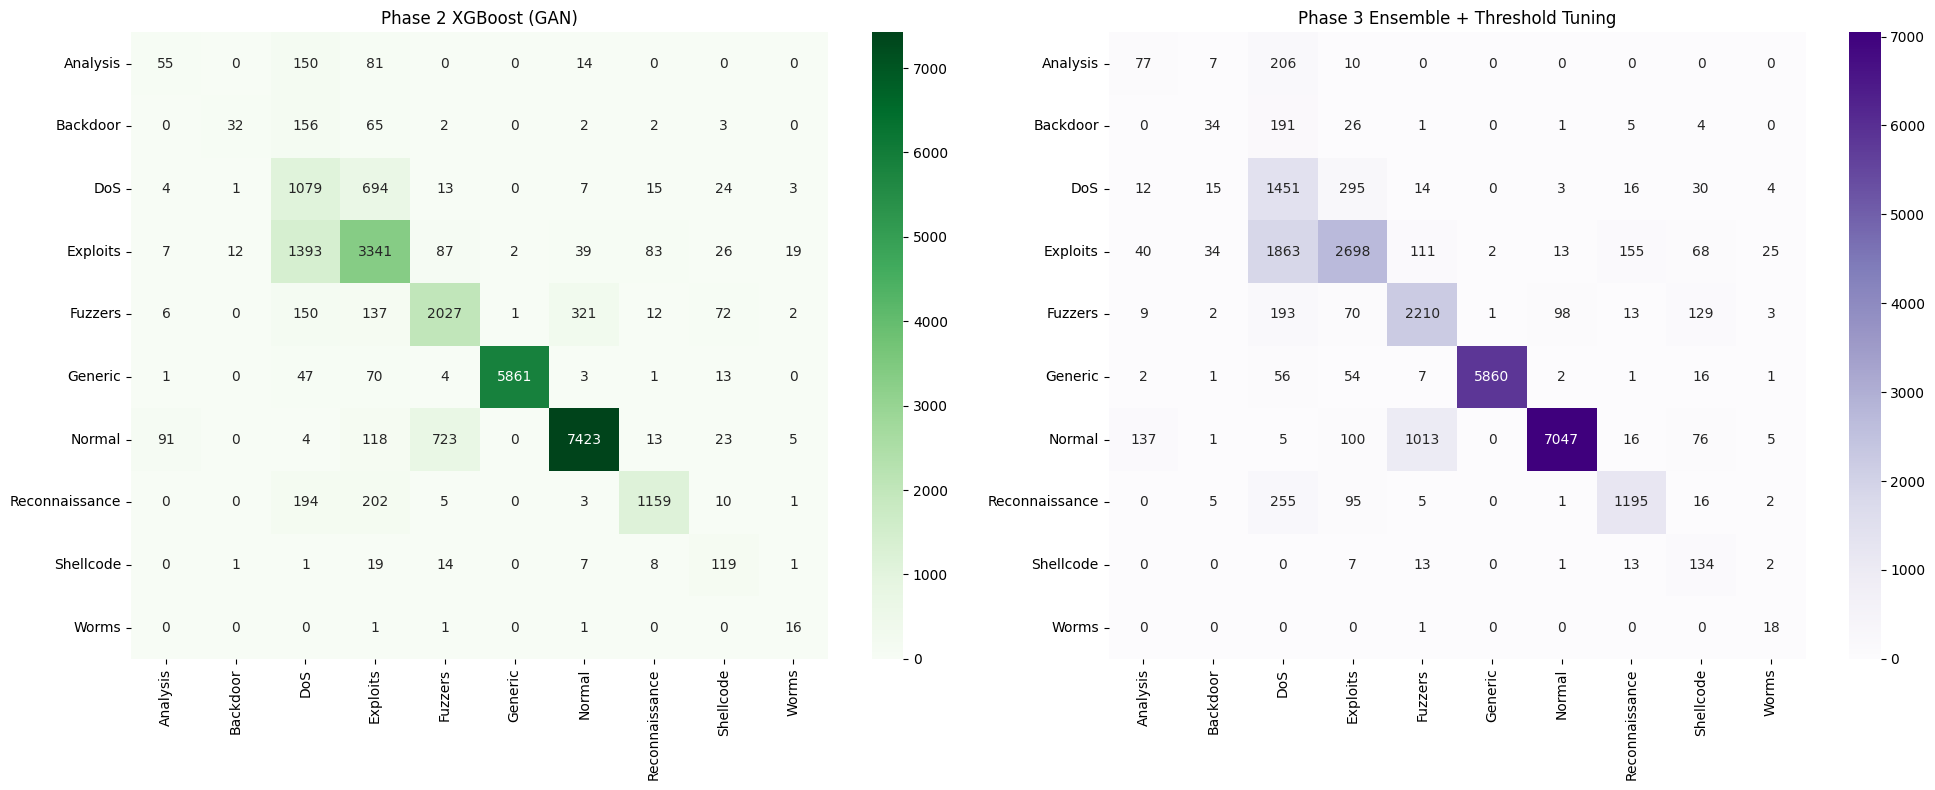

: 

In [ ]:
# Confusion Matrix Comparison (Phase 2 vs Phase 3)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Phase 2
sns.heatmap(confusion_matrix(y_test_enc, y_pred_v2), annot=True, fmt='d', cmap='Greens', ax=axes[0], xticklabels=classes, yticklabels=classes)
axes[0].set_title('Phase 2 XGBoost (GAN)')

# Phase 3
sns.heatmap(confusion_matrix(y_test_enc, y_pred_tuned), annot=True, fmt='d', cmap='Purples', ax=axes[1], xticklabels=classes, yticklabels=classes)
axes[1].set_title('Phase 3 Ensemble + Threshold Tuning')

plt.tight_layout()
plt.show()
